# Conditioned Pantun Transformer — Launcher & Training Metrics Tracker
1. Download the repo archive from public GitHub
2. Train & capture real-time stdout metrics without modifying `train.py`
3. Parse logs, export `training_history.json` / `step_metrics.csv` / `eval_metrics.csv`, and generate comprehensive plots (Train/Val Loss, LR Curve, Gradient Norm, Perplexity, Pantun Quality Metrics, & Dual X-Axis Steps/Epoch)
4. Upload checkpoints (`*.pt`), metric logs, and plots to Hugging Face

**Kaggle setup:** Settings → Internet **On** (needed for GitHub, tiktoken's GPT-2 BPE download and Hugging Face), Accelerator → GPU T4 x2, and add a secret named `HF_TOKEN` (write access) under Add-ons → Secrets.

In [1]:
# ---------- CONFIG ----------
GITHUB_OWNER = "krisnaganesha1609"
GITHUB_REPO  = "Conditioned-Pantun-Transformer"
GITHUB_REF   = "main"              # branch or tag
HF_REPO_ID   = "igkganes/conditioned-pantun-transformer"
HF_PRIVATE   = False

TRAIN_ARGS = {
    "batch_size": 32,
    "grad_accum_steps": 2,         # effective batch 64
    "warmup_steps": 600,
    "max_steps": 10000,
    "eval_interval": 250,
    "eval_iters": 100,
    "lr": "6e-4",
    "min_lr": "6e-5",
}
RUN_SMOKE_TEST = False
UPLOAD_PLOTS_AND_LOGS = True       # Set False jika hanya ingin upload *.pt murni

In [2]:
# Torch, matplotlib, & pandas are preinstalled on Kaggle/Colab; only the extras are needed.
# (repo requirements.txt is UTF-16 with pinned versions, so it is deliberately not used)
!pip install -q tokenizers huggingface_hub matplotlib pandas

In [3]:
# ---------- 1. Pull the archive from public GitHub ----------
import io, os, shutil, urllib.request, zipfile

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
os.chdir(WORK)

url = f"https://github.com/{GITHUB_OWNER}/{GITHUB_REPO}/archive/{GITHUB_REF}.zip"
print("Downloading", url)
with urllib.request.urlopen(url, timeout=120) as r:
    data = r.read()

REPO_DIR = os.path.join(WORK, GITHUB_REPO)
if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)

with zipfile.ZipFile(io.BytesIO(data)) as z:
    top = z.namelist()[0].split("/")[0]        # e.g. Repo-main
    z.extractall(WORK)
os.rename(os.path.join(WORK, top), REPO_DIR)
os.chdir(REPO_DIR)
print(f"Extracted {len(data)/1e6:.1f} MB -> {REPO_DIR}")
assert os.path.exists("3.TRAINING/train.py"), "train.py not found in archive"

Extracted 3.1 MB -> /kaggle/working/Conditioned-Pantun-Transformer


In [4]:
# ---------- Hugging Face login ----------
import os
from huggingface_hub import login

token = os.environ.get("HF_TOKEN")
if not token:
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")
        except Exception:
            pass
assert token, "HF_TOKEN not found (Kaggle Secret, Colab secret, or env var)."
login(token=token)
print("Logged in to Hugging Face.")

Logged in to Hugging Face.


In [5]:
# ---------- 2a. Subprocess Runner & Log Capture Setup ----------
import subprocess, sys, shutil, os

def run(cmd, log_path=None):
    """Menjalankan command secara streaming ke layar sekaligus menyimpan stdout ke file log."""
    lines = []
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    log_file = open(log_path, "w", encoding="utf-8") if log_path else None
    try:
        for line in p.stdout:
            print(line, end="")
            lines.append(line)
            if log_file:
                log_file.write(line)
                log_file.flush()
    finally:
        if log_file:
            log_file.close()
    if p.wait() != 0:
        raise RuntimeError(f"Command failed with exit code {p.returncode}")
    return lines

CKPT_DIR = "3.TRAINING/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

if RUN_SMOKE_TEST:
    run([sys.executable, "3.TRAINING/train.py", "--smoke_test"])
    # the smoke test writes a 2-step last.pt; remove it so it can never be uploaded
    shutil.rmtree(CKPT_DIR, ignore_errors=True)
    os.makedirs(CKPT_DIR, exist_ok=True)

In [6]:
# ---------- 2b. Full training (with stdout logging) ----------
os.makedirs(CKPT_DIR, exist_ok=True)
LOG_FILE = os.path.join(CKPT_DIR, "train_stdout.log")

cmd = [sys.executable, "3.TRAINING/train.py"]
for k, v in TRAIN_ARGS.items():
    cmd += [f"--{k}", str(v)]
print(" ".join(cmd))
train_logs = run(cmd, log_path=LOG_FILE)

/usr/bin/python3 3.TRAINING/train.py --batch_size 32 --grad_accum_steps 2 --warmup_steps 600 --max_steps 10000 --eval_interval 250 --eval_iters 100 --lr 6e-4 --min_lr 6e-5
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
[Init] Using device: cuda
LAPORAN PANJANG TOKEN (Syllable-Bounded BPE)
Sampel            : 10,492
Mean / P99 / Max  : 54.1 / 65 / 85
Token per kata    : 3.10 (termasuk special token)
Vocab aktual      : 1809
Rekomendasi BLOCK_SIZE : 128
[Data] train.txt: 10,492 valid | 0 format salah | 9 ditolak filter bahasa
[Data] val.txt: 1,313 valid | 0 format salah | 0 ditolak filter bahasa
[Init] Train samples: 10,492 (/kaggle/working/Conditioned-Pantun-Transformer/1.DATASET/processed_data/train.txt)
[Init] Val samples  : 1,313 (/kaggle/working/Conditioned-Pantun-Tra

=== RINGKASAN KONFIGURASI EPOCH & STEP ===
Train Samples        : 10,492
Effective Batch Size : 64 (batch_size=32 x grad_accum=2)
Steps / Epoch        : 163.50 steps/epoch
Total Max Steps      : 10000 steps (~61.16 epochs)


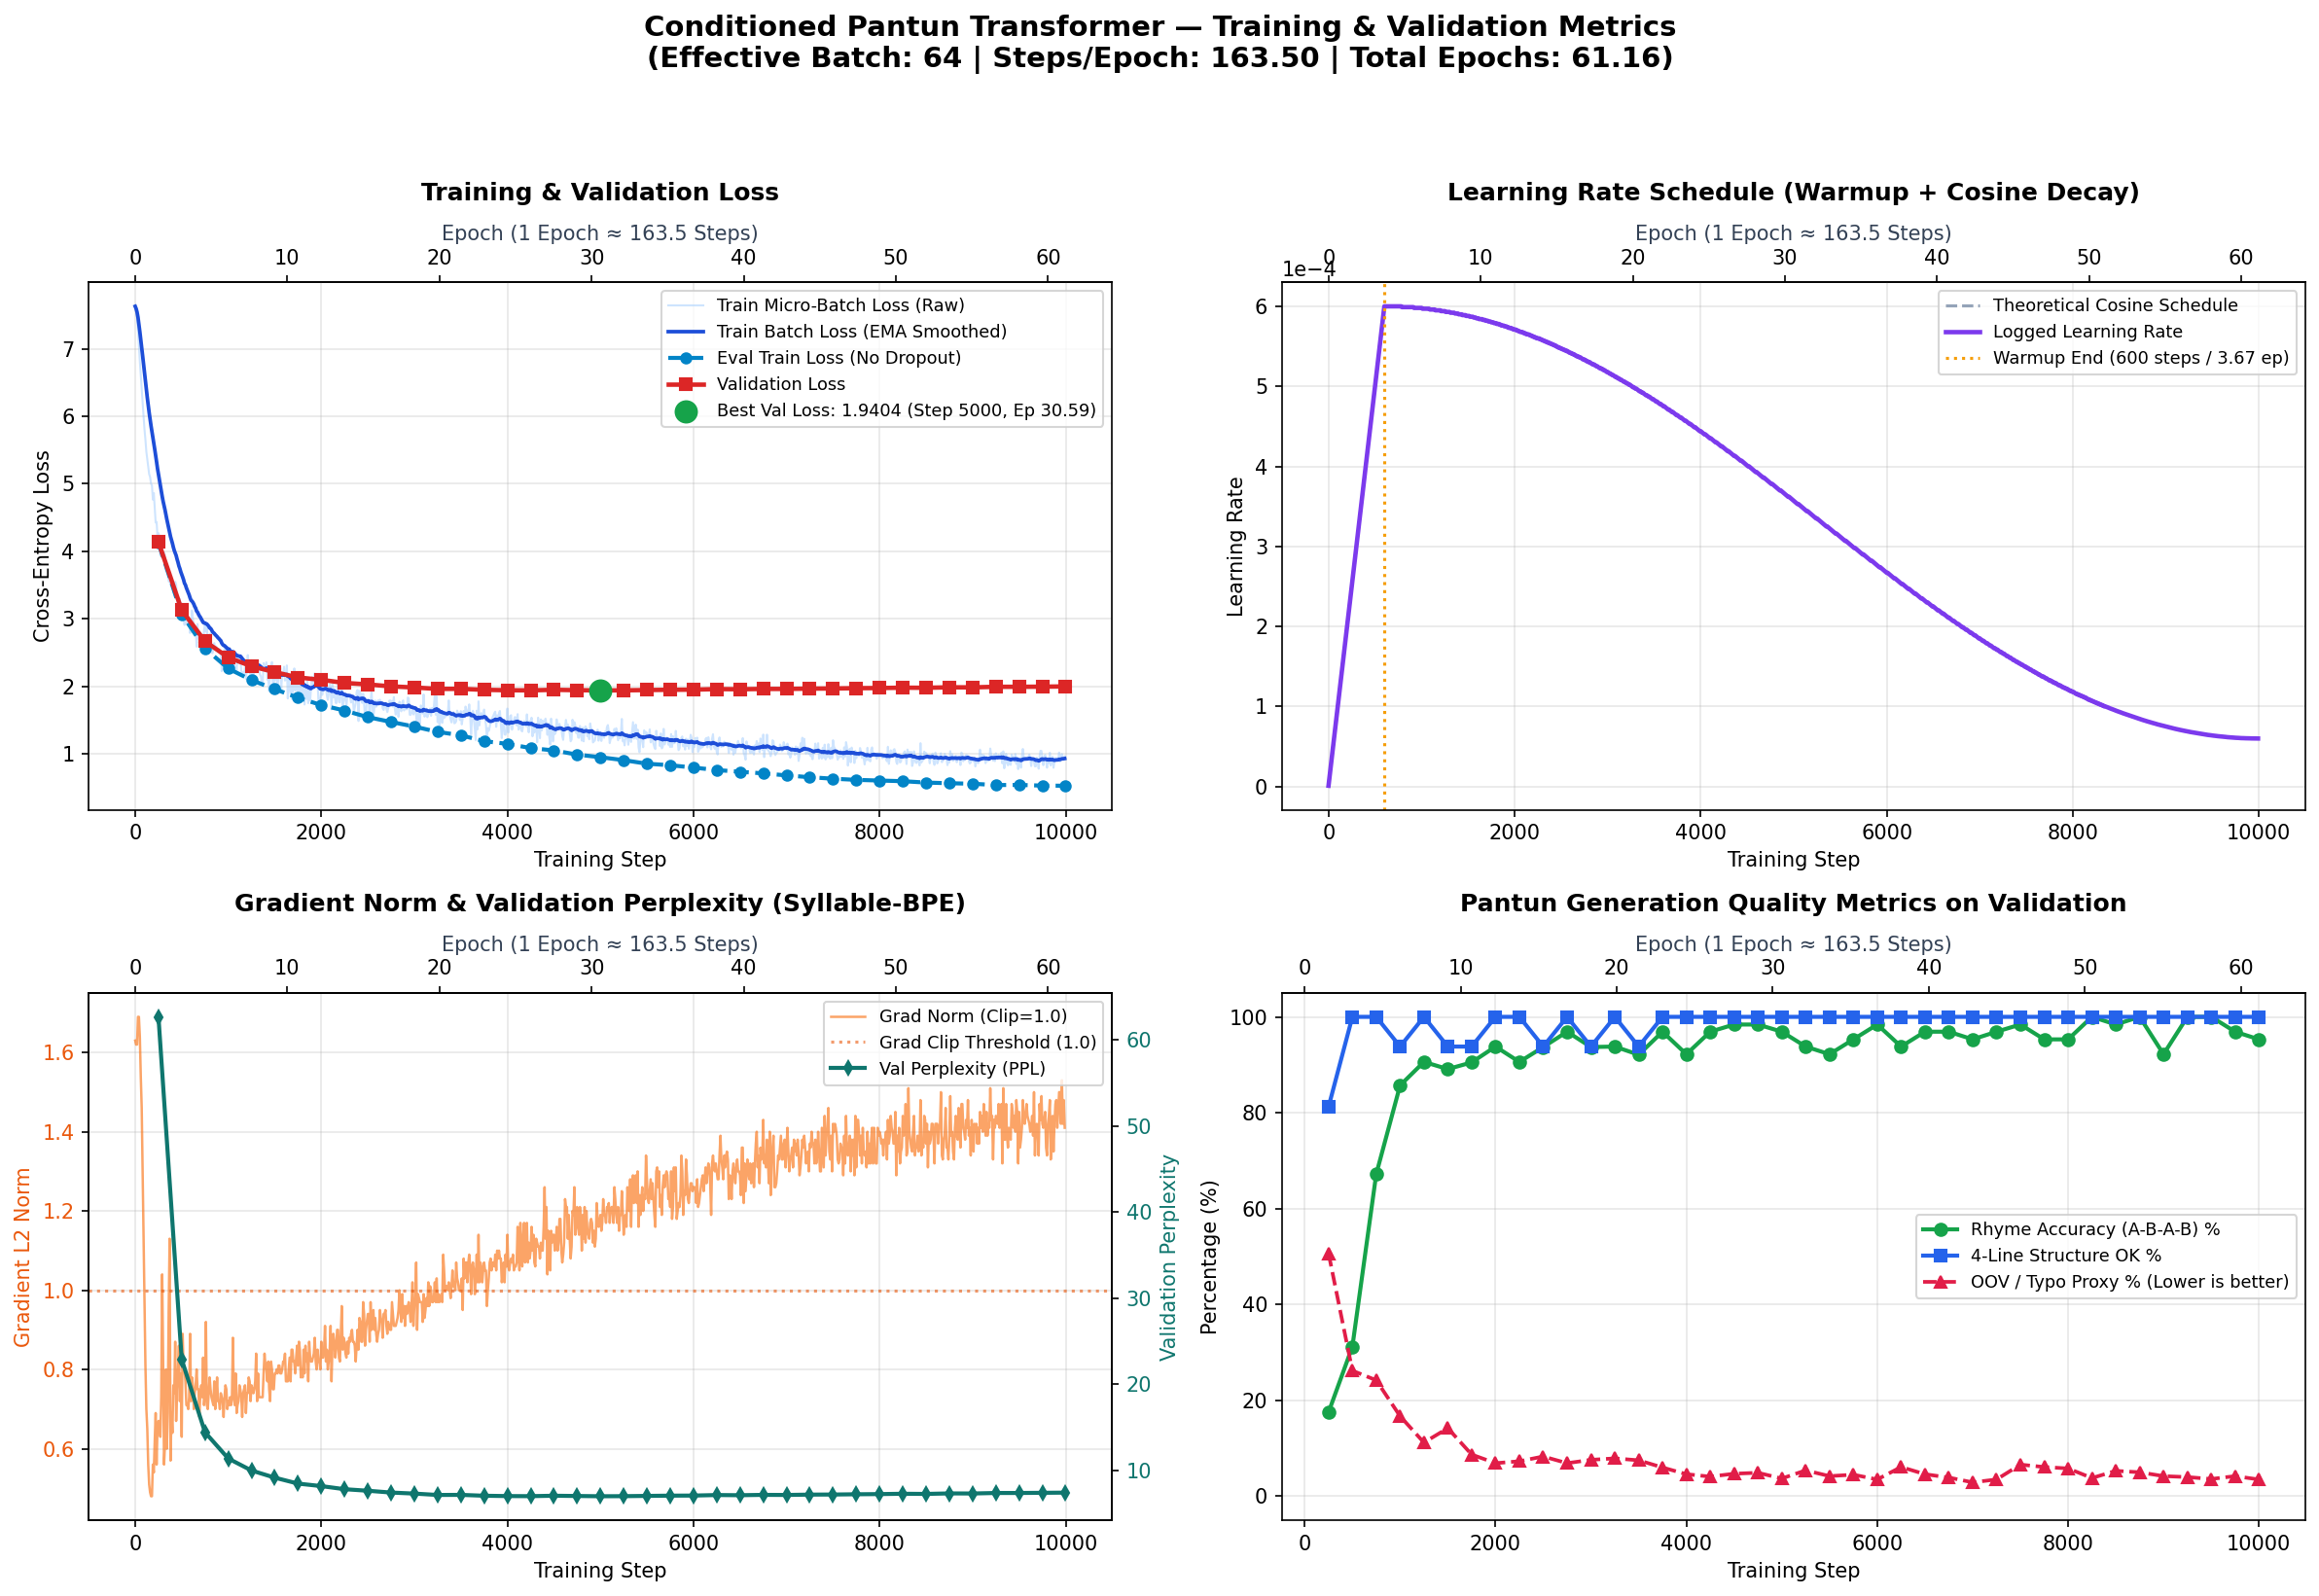


Saved plots & logs to 3.TRAINING/checkpoints:
  - training_metrics_dashboard.png
  - loss_curve.png
  - lr_schedule_curve.png
  - step_metrics.csv
  - eval_metrics.csv
  - training_history.json

=== TABEL EVALUASI PER INTERVAL ===
 step     epoch  train_loss  val_loss  val_ppl  rhyme_acc  struct_ok  oov_rate
  250  1.535168      4.1254    4.1381    62.68       17.5       81.2      50.7
  500  3.064220      3.0677    3.1292    22.86       31.2      100.0      26.2
  750  4.593272      2.5620    2.6671    14.40       67.2      100.0      24.2
 1000  6.122324      2.2641    2.4288    11.35       85.7       93.8      16.7
 1250  7.651376      2.0924    2.2974     9.95       90.6      100.0      11.2
 1500  9.180428      1.9600    2.2110     9.12       89.1       93.8      14.2
 1750 10.709480      1.8307    2.1320     8.43       90.5       93.8       8.7
 2000 12.238532      1.7237    2.0967     8.14       93.8      100.0       6.9
 2250 13.767584      1.6416    2.0510     7.78       90.6

In [7]:
# ---------- 2c. Parse Training Logs & Plot Metrics (Loss, LR, Steps/Epoch) ----------
import re, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Regex patterns sesuai format stdout dari train.py
re_init_train = re.compile(r"\[Init\] Train samples:\s*([\d,]+)")
re_init_val   = re.compile(r"\[Init\] Val samples\s*:\s*([\d,]+)")
re_init_vocab = re.compile(r"\[Init\] Vocab size\s*:\s*(\d+)")
re_step       = re.compile(r"Step\s+(\d+)\s*\|\s*Loss:\s*([\d.]+)\s*\|\s*LR:\s*([\d.eE+-]+)\s*\|\s*Norm:\s*([\d.]+)\s*\|\s*Tok/s:\s*([\d.]+)")
re_eval_hdr   = re.compile(r"--- EVAL STEP (\d+) ---")
re_eval_loss  = re.compile(r"Train Loss:\s*([\d.]+)\s*\|\s*Val Loss:\s*([\d.]+)\s*\|\s*Val PPL \(syllable-BPE\):\s*([\d.]+)")
re_eval_qual  = re.compile(r"Rhyme Acc:\s*([\d.]+)%\s*\|\s*4-Line OK:\s*([\d.]+)%\s*\|\s*OOV/Typo proxy:\s*([\d.]+)%")

# Baca log dari memory atau dari file jika cell dijalankan terpisah
if "train_logs" not in globals() or not train_logs:
    with open(LOG_FILE, "r", encoding="utf-8") as f:
        train_logs = f.readlines()

train_samples = None
val_samples = None
vocab_size = None
step_records = []
eval_records = []
curr_eval = None

for line in train_logs:
    m = re_init_train.search(line)
    if m:
        train_samples = int(m.group(1).replace(",", ""))
    m = re_init_val.search(line)
    if m:
        val_samples = int(m.group(1).replace(",", ""))
    m = re_init_vocab.search(line)
    if m:
        vocab_size = int(m.group(1))

    m = re_step.search(line)
    if m:
        step_records.append({
            "step": int(m.group(1)),
            "train_batch_loss": float(m.group(2)),
            "lr": float(m.group(3)),
            "grad_norm": float(m.group(4)),
            "tok_per_sec": float(m.group(5)),
        })
        continue

    m = re_eval_hdr.search(line)
    if m:
        curr_eval = {"step": int(m.group(1))}
        continue

    if curr_eval is not None:
        m_loss = re_eval_loss.search(line)
        if m_loss:
            curr_eval["train_loss"] = float(m_loss.group(1))
            curr_eval["val_loss"]   = float(m_loss.group(2))
            curr_eval["val_ppl"]    = float(m_loss.group(3))
            continue
        m_qual = re_eval_qual.search(line)
        if m_qual:
            curr_eval["rhyme_acc"] = float(m_qual.group(1))
            curr_eval["struct_ok"] = float(m_qual.group(2))
            curr_eval["oov_rate"]  = float(m_qual.group(3))
            eval_records.append(curr_eval)
            curr_eval = None

# 2. Kalkulasi Steps per Epoch & Konversi Step <-> Epoch
# Di train.py: DataLoader(..., batch_size=args.batch_size, drop_last=True)
# Setiap optimization step mengonsumsi `grad_accum_steps` micro-batches.
batch_size = int(TRAIN_ARGS.get("batch_size", 32))
grad_accum = int(TRAIN_ARGS.get("grad_accum_steps", 1))
eff_batch_size = batch_size * grad_accum

if train_samples and train_samples > 0:
    batches_per_epoch = train_samples // batch_size  # karena drop_last=True di train_loader
    steps_per_epoch = batches_per_epoch / grad_accum
else:
    steps_per_epoch = 1.0

for r in step_records:
    r["epoch"] = (r["step"] + 1) / steps_per_epoch
for r in eval_records:
    r["epoch"] = (r["step"] + 1) / steps_per_epoch

df_steps = pd.DataFrame(step_records)
df_eval  = pd.DataFrame(eval_records)

# Simpan metrik ke CSV & JSON di dalam folder checkpoints
os.makedirs(CKPT_DIR, exist_ok=True)
df_steps.to_csv(os.path.join(CKPT_DIR, "step_metrics.csv"), index=False)
df_eval.to_csv(os.path.join(CKPT_DIR, "eval_metrics.csv"), index=False)

history_meta = {
    "train_samples": train_samples,
    "val_samples": val_samples,
    "vocab_size": vocab_size,
    "effective_batch_size": eff_batch_size,
    "steps_per_epoch": round(steps_per_epoch, 4),
    "total_epochs_completed": round(int(TRAIN_ARGS["max_steps"]) / steps_per_epoch, 4),
    "train_args": TRAIN_ARGS,
    "step_metrics": step_records,
    "eval_metrics": eval_records,
}
with open(os.path.join(CKPT_DIR, "training_history.json"), "w", encoding="utf-8") as f:
    json.dump(history_meta, f, indent=2)

print(f"=== RINGKASAN KONFIGURASI EPOCH & STEP ===")
print(f"Train Samples        : {train_samples:,}" if train_samples else "Train Samples: N/A")
print(f"Effective Batch Size : {eff_batch_size} (batch_size={batch_size} x grad_accum={grad_accum})")
print(f"Steps / Epoch        : {steps_per_epoch:.2f} steps/epoch")
print(f"Total Max Steps      : {TRAIN_ARGS['max_steps']} steps (~{int(TRAIN_ARGS['max_steps'])/steps_per_epoch:.2f} epochs)")

# 3. rekonstruksi Kurva LR Teoritis penuh (Cosine Decay + Linear Warmup sesuai get_lr di train.py)
max_steps_cfg = int(TRAIN_ARGS["max_steps"])
warmup_cfg    = int(TRAIN_ARGS["warmup_steps"])
lr_max_cfg    = float(TRAIN_ARGS["lr"])
lr_min_cfg    = float(TRAIN_ARGS["min_lr"])

def theoretical_lr(step):
    if step < warmup_cfg:
        return lr_max_cfg * (step + 1) / warmup_cfg
    if step > max_steps_cfg:
        return lr_min_cfg
    decay_ratio = (step - warmup_cfg) / max(1, (max_steps_cfg - warmup_cfg))
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return lr_min_cfg + coeff * (lr_max_cfg - lr_min_cfg)

all_steps = np.arange(0, max_steps_cfg)
all_lrs   = [theoretical_lr(s) for s in all_steps]

# Helper untuk membuat sumbu X ganda (bawah: Step, atas: Epoch)
def add_epoch_top_axis(ax):
    secax = ax.secondary_xaxis("top", functions=(lambda s: s / steps_per_epoch, lambda e: e * steps_per_epoch))
    secax.set_xlabel(f"Epoch (1 Epoch ≈ {steps_per_epoch:.1f} Steps)", fontsize=10, color="#334155")
    return secax

# 4. PLOTTING: Dashboard 2x2 Komprehensif
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=150)
fig.suptitle(
    f"Conditioned Pantun Transformer — Training & Validation Metrics\n"
    f"(Effective Batch: {eff_batch_size} | Steps/Epoch: {steps_per_epoch:.2f} | Total Epochs: {max_steps_cfg/steps_per_epoch:.2f})",
    fontsize=14, fontweight="bold", y=0.99
)

# Panel (0,0): Training Loss vs Validation Loss
ax1 = axes[0, 0]
if not df_steps.empty:
    ax1.plot(df_steps["step"], df_steps["train_batch_loss"], color="#93c5fd", alpha=0.45, linewidth=1.0, label="Train Micro-Batch Loss (Raw)")
    if len(df_steps) >= 5:
        ema_loss = df_steps["train_batch_loss"].ewm(span=min(25, len(df_steps))).mean()
        ax1.plot(df_steps["step"], ema_loss, color="#1d4ed8", linewidth=1.8, label="Train Batch Loss (EMA Smoothed)")
if not df_eval.empty:
    ax1.plot(df_eval["step"], df_eval["train_loss"], "o--", color="#0284c7", linewidth=2.0, markersize=5, label="Eval Train Loss (No Dropout)")
    ax1.plot(df_eval["step"], df_eval["val_loss"], "s-", color="#dc2626", linewidth=2.2, markersize=6, label="Validation Loss")
    best_idx = df_eval["val_loss"].idxmin()
    best_row = df_eval.loc[best_idx]
    ax1.scatter([best_row["step"]], [best_row["val_loss"]], color="#16a34a", s=110, zorder=6,
                label=f"Best Val Loss: {best_row['val_loss']:.4f} (Step {int(best_row['step'])}, Ep {best_row['epoch']:.2f})")
ax1.set_title("Training & Validation Loss", fontweight="bold", pad=12)
ax1.set_xlabel("Training Step")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.legend(loc="upper right", fontsize=8.5)
add_epoch_top_axis(ax1)

# Panel (0,1): Learning Rate Schedule (Linear Warmup + Cosine Decay)
ax2 = axes[0, 1]
ax2.plot(all_steps, all_lrs, "--", color="#94a3b8", linewidth=1.5, label="Theoretical Cosine Schedule")
if not df_steps.empty:
    ax2.plot(df_steps["step"], df_steps["lr"], color="#7c3aed", linewidth=2.2, label="Logged Learning Rate")
ax2.axvline(warmup_cfg, color="#f59e0b", linestyle=":", linewidth=1.5, label=f"Warmup End ({warmup_cfg} steps / {warmup_cfg/steps_per_epoch:.2f} ep)")
ax2.set_title("Learning Rate Schedule (Warmup + Cosine Decay)", fontweight="bold", pad=12)
ax2.set_xlabel("Training Step")
ax2.set_ylabel("Learning Rate")
ax2.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
ax2.legend(loc="upper right", fontsize=8.5)
add_epoch_top_axis(ax2)

# Panel (1,0): Validation Perplexity & Gradient Norm
ax3 = axes[1, 0]
if not df_steps.empty:
    ax3.plot(df_steps["step"], df_steps["grad_norm"], color="#f97316", alpha=0.65, linewidth=1.2, label="Grad Norm (Clip=1.0)")
    ax3.axhline(1.0, color="#ea580c", linestyle=":", alpha=0.6, label="Grad Clip Threshold (1.0)")
ax3.set_title("Gradient Norm & Validation Perplexity (Syllable-BPE)", fontweight="bold", pad=12)
ax3.set_xlabel("Training Step")
ax3.set_ylabel("Gradient L2 Norm", color="#ea580c")
ax3.tick_params(axis="y", labelcolor="#ea580c")

if not df_eval.empty:
    ax3_twin = ax3.twinx()
    ax3_twin.plot(df_eval["step"], df_eval["val_ppl"], "d-", color="#0f766e", linewidth=2.0, markersize=5, label="Val Perplexity (PPL)")
    ax3_twin.set_ylabel("Validation Perplexity", color="#0f766e")
    ax3_twin.tick_params(axis="y", labelcolor="#0f766e")
    ax3_twin.grid(False)
    lines1, labels1 = ax3.get_legend_handles_labels()
    lines2, labels2 = ax3_twin.get_legend_handles_labels()
    ax3.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=8.5)
else:
    ax3.legend(loc="upper right", fontsize=8.5)
add_epoch_top_axis(ax3)

# Panel (1,1): Pantun Generation Quality Metrics (Rhyme Acc, 4-Line Struct, OOV/Typo Rate)
ax4 = axes[1, 1]
if not df_eval.empty:
    ax4.plot(df_eval["step"], df_eval["rhyme_acc"], "o-", color="#16a34a", linewidth=2.0, label="Rhyme Accuracy (A-B-A-B) %")
    ax4.plot(df_eval["step"], df_eval["struct_ok"], "s-", color="#2563eb", linewidth=2.0, label="4-Line Structure OK %")
    ax4.plot(df_eval["step"], df_eval["oov_rate"], "^--", color="#e11d48", linewidth=1.8, label="OOV / Typo Proxy % (Lower is better)")
ax4.set_title("Pantun Generation Quality Metrics on Validation", fontweight="bold", pad=12)
ax4.set_xlabel("Training Step")
ax4.set_ylabel("Percentage (%)")
ax4.set_ylim(-5, 105)
ax4.legend(loc="center right", fontsize=8.5)
add_epoch_top_axis(ax4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
dashboard_path = os.path.join(CKPT_DIR, "training_metrics_dashboard.png")
plt.savefig(dashboard_path, bbox_inches="tight")
plt.show()

# 5. Plot Terpisah Khusus Laporan Skripsi/Tugas Akhir (Loss & LR + Dual Axis Step/Epoch)
fig_loss, ax_l = plt.subplots(figsize=(9, 5.5), dpi=150)
if not df_steps.empty:
    ax_l.plot(df_steps["step"], df_steps["train_batch_loss"], color="#bfdbfe", alpha=0.5, label="Train Batch Loss (Step)")
if not df_eval.empty:
    ax_l.plot(df_eval["step"], df_eval["train_loss"], "o--", color="#1d4ed8", linewidth=2, label="Train Loss (Eval)")
    ax_l.plot(df_eval["step"], df_eval["val_loss"], "s-", color="#dc2626", linewidth=2.2, label="Validation Loss (Eval)")
ax_l.set_title("Training vs Validation Loss Curve", fontweight="bold", pad=12)
ax_l.set_xlabel("Optimization Steps")
ax_l.set_ylabel("Cross-Entropy Loss")
ax_l.legend()
add_epoch_top_axis(ax_l)
plt.tight_layout()
loss_plot_path = os.path.join(CKPT_DIR, "loss_curve.png")
plt.savefig(loss_plot_path, bbox_inches="tight")
plt.close(fig_loss)

fig_lr, ax_r = plt.subplots(figsize=(9, 5), dpi=150)
ax_r.plot(all_steps, all_lrs, "--", color="#94a3b8", label="Scheduled LR")
if not df_steps.empty:
    ax_r.plot(df_steps["step"], df_steps["lr"], color="#7c3aed", linewidth=2, label="Actual LR")
ax_r.axvline(warmup_cfg, color="#f59e0b", linestyle=":", label=f"Warmup ({warmup_cfg} steps)")
ax_r.set_title("Learning Rate vs Steps & Epochs", fontweight="bold", pad=12)
ax_r.set_xlabel("Optimization Steps")
ax_r.set_ylabel("Learning Rate")
ax_r.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
ax_r.legend()
add_epoch_top_axis(ax_r)
plt.tight_layout()
lr_plot_path = os.path.join(CKPT_DIR, "lr_schedule_curve.png")
plt.savefig(lr_plot_path, bbox_inches="tight")
plt.close(fig_lr)

print(f"\nSaved plots & logs to {CKPT_DIR}:")
for fname in ["training_metrics_dashboard.png", "loss_curve.png", "lr_schedule_curve.png", "step_metrics.csv", "eval_metrics.csv", "training_history.json"]:
    print(f"  - {fname}")

if not df_eval.empty:
    print("\n=== TABEL EVALUASI PER INTERVAL ===")
    display_cols = ["step", "epoch", "train_loss", "val_loss", "val_ppl", "rhyme_acc", "struct_ok", "oov_rate"]
    print(df_eval[display_cols].to_string(index=False))

In [8]:
# ---------- 3. Upload Checkpoints (& dokumentasi grafik/log) ke Hugging Face ----------
import os, time
from huggingface_hub import HfApi

ckpts = sorted(f for f in os.listdir(CKPT_DIR) if f.endswith(".pt"))
assert ckpts, f"No .pt checkpoints found in {CKPT_DIR}"
print("Checkpoints found:", ckpts)

api = HfApi()
api.create_repo(repo_id=HF_REPO_ID, repo_type="model", private=HF_PRIVATE, exist_ok=True)

# Nama run: isi manual lewat env var RUN_NAME, kalau kosong pakai timestamp UTC
RUN_NAME = os.environ.get("RUN_NAME") or time.strftime("run-%Y%m%d-%H%M%S", time.gmtime())

# Cari folder tujuan yang belum dipakai di repo
existing_files = api.list_repo_files(HF_REPO_ID, repo_type="model")

def is_taken(path: str) -> bool:
    return any(f.startswith(path + "/") for f in existing_files)

dest = f"checkpoints/{RUN_NAME}"
suffix = 2
while is_taken(dest):
    dest = f"checkpoints/{RUN_NAME}-{suffix}"
    suffix += 1

allow_patterns = ["*.pt", "*.png", "*.csv", "*.json", "*.log"] if UPLOAD_PLOTS_AND_LOGS else ["*.pt"]

api.upload_folder(
    folder_path=CKPT_DIR,
    repo_id=HF_REPO_ID,
    repo_type="model",
    path_in_repo=dest,
    allow_patterns=allow_patterns,
    # sengaja TIDAK memakai delete_patterns, jadi tidak ada file lama yang dihapus
    commit_message=f"Add checkpoints & training metrics: {dest}",
)
print(f"Done: https://huggingface.co/{HF_REPO_ID}/tree/main/{dest}")

Checkpoints found: ['best.pt', 'last.pt']
Done: https://huggingface.co/igkganes/conditioned-pantun-transformer/tree/main/checkpoints/run-20261103-151322
